# Hidden Marker Lab: experiments and replication

This notebook asks a specific operational question about access to internal activations. While Qwen reads a sentence, we add a vector to one location in its residual stream, the sequence of hidden representations that carries information from one transformer block to the next. Nothing in the written carrier sentence identifies which vector was added. We then test whether the model can use the resulting internal difference when it answers a question later in the same prompt.

In one episode, the model reads the same carrier sentence three times. We add vector $v_1$ to the model's residual stream during the first occurrence and call that marker `dax`. We add a different vector $v_2$ during the second occurrence and call that marker `wug`. During the test occurrence, we add either $v_1$ or $v_2$. The model must report the corresponding label.

```text
Example 1: The copper lantern stood beside the window.  + v1  -> dax
Example 2: The copper lantern stood beside the window.  + v2  -> wug
Test:      The copper lantern stood beside the window.  + v?  -> A or B
```

Within an episode, the carrier sentence is repeated verbatim in both demonstrations and in the test. The names `dax` and `wug` are nonce labels, so they do not have a useful meaning before the demonstrations assign one. Holding the carrier wording fixed removes an ordinary textual route to the answer: to select the right label at test, the model must preserve information about the intervention applied during each demonstration and compare the test intervention with those examples.

The notebook begins by testing the unmodified model with both A/B and YES/NO questions. It then trains LoRA adapters on newly generated episodes, tests whether the learned behavior transfers to new vectors and new experimental settings, and uses attention analysis, ablation, and activation patching to investigate which parts of the trained model contribute to the result. Each section keeps the functional claim narrow: success on this task shows that the model can learn to report these controlled residual-stream interventions under the tested conditions, not that it has general access to every aspect of its internal computation.

## Experimental setup

The model is unquantized `Qwen/Qwen3-14B` in BF16. Qwen3-14B has 40 transformer blocks and a residual width of 5,120. The intervention is applied to the residual input of block 20, at the token containing the final period of the carrier sentence.

For a residual activation $h_{\ell,t}\in\mathbb{R}^{5120}$, the intervention is

$$
h'_{\ell,t}=h_{\ell,t}+\alpha v.
$$

The vector $v$ has unit norm. The scale is $\alpha=\rho R_\ell$, where $R_\ell$ is the median residual norm measured at the same site on ordinary carrier sentences. The base experiments use $\rho=0.1$.

The model receives no intervention on the demonstrations' answers, the question, the answer prefix, or the answer tokens. We score the next-token logits directly and do not sample text.

| Item | Setting |
|---|---|
| Model | `Qwen/Qwen3-14B`, BF16, unquantized |
| Transformer block | 20 of 40, using zero-based indexing |
| Hook location | residual input, `resid_pre` |
| Token | final period of each carrier sentence |
| Base strength | $\rho=0.1$ |
| Direction sampling | fresh FP32 orthonormal pair per episode |
| Decoding | deterministic next-token logit comparison |
| Training | LoRA on blocks 20 through 39; base weights frozen |

## Running this notebook

This `.ipynb` file is self-contained for its default analysis mode. It carries a compressed copy of the recorded result summaries, the experiment runners, and the local Athena interface. The first two code cells unpack those resources into a versioned temporary directory and install a missing core Python package if necessary. They do not download model weights or start a GPU job.

The notebook has two execution modes. With `RUN_GPU_EXPERIMENTS = False`, it reads the embedded recorded results and reproduces every analysis and figure on an ordinary CPU machine. This is the default because the complete study takes many H100-hours. Choose **Restart Kernel and Run All Cells** to verify this path from a clean kernel.

Set `RUN_GPU_EXPERIMENTS = True` to rerun the model experiments. Set `RUN_MECHANISTIC_ANALYSIS = True` as well to rerun the attention screens, ablations, and activation patches. One 80 GB H100 can run each job. The notebook runs jobs in order. The independent training seeds can also be launched concurrently as separate jobs.

The cells below define the prompts, vector sampling, token-location logic, intervention hook, candidate-token checks, logit scoring, LoRA modules, and training step directly. The command-line calls later in the notebook handle checkpointing and long multi-seed sweeps with the same definitions.

### Prepare the embedded support files

The next cell contains a compressed payload and is hidden by default because the encoded bytes are not useful to read. The following visible cell verifies its SHA-256 digest, extracts it to the system temporary directory, and adds that directory to Python's import path. This is what allows a downloaded copy of the notebook to run without being placed inside the Git repository.

In [1]:
_EMBEDDED_SUPPORT_B64 = "..."
_EMBEDDED_SUPPORT_SHA256 = "ab6be60af932025ec5ce21c988a9cfb16390d5c500ac0506c6192fed5feb4d48"

In [2]:
import base64
import hashlib
import importlib.util
import io
import subprocess
import sys
import tempfile
import zipfile
from pathlib import Path

# These are the only packages needed for the default CPU analysis. Jupyter
# already supplies IPython. We install a package only when it is absent.
_CORE_PACKAGES = {
    "numpy": "numpy>=1.26,<3",
    "matplotlib": "matplotlib>=3.8,<4",
    "torch": "torch>=2.4",
}
_missing_packages = [
    requirement
    for module, requirement in _CORE_PACKAGES.items()
    if importlib.util.find_spec(module) is None
]
if _missing_packages:
    print("Installing missing notebook packages:", ", ".join(_missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing_packages])

_support_bytes = base64.b64decode(_EMBEDDED_SUPPORT_B64)
_support_digest = hashlib.sha256(_support_bytes).hexdigest()
if _support_digest != _EMBEDDED_SUPPORT_SHA256:
    raise RuntimeError("The notebook's embedded support bundle failed its SHA-256 check")

NOTEBOOK_PROJECT_ROOT = (
    Path(tempfile.gettempdir())
    / f"hidden-marker-lab-notebook-{_support_digest[:12]}"
)
_ready_marker = NOTEBOOK_PROJECT_ROOT / ".ready"
if not _ready_marker.exists():
    NOTEBOOK_PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(_support_bytes)) as _archive:
        _root_resolved = NOTEBOOK_PROJECT_ROOT.resolve()
        for _member in _archive.namelist():
            _target = (NOTEBOOK_PROJECT_ROOT / _member).resolve()
            if _target != _root_resolved and _root_resolved not in _target.parents:
                raise RuntimeError(f"Unsafe path in embedded support bundle: {_member}")
        _archive.extractall(NOTEBOOK_PROJECT_ROOT)
    _ready_marker.write_text(_support_digest, encoding="utf-8")

if str(NOTEBOOK_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_PROJECT_ROOT))

print("Embedded support files are ready:", NOTEBOOK_PROJECT_ROOT)

Embedded support files are ready: /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932


## Optional local interface

The source bundle includes a separate browser interface called **Residual Marker Studio**. It is designed for direct experimentation rather than for displaying the completed results. The interface lets you enter a free-form message, view the exact model tokens, and mark any token positions with either of two freshly sampled residual directions. It can run the base model, any of the three fixed-site LoRA replications, or the cross-layer LoRA adapter, and it can place base and trained outputs beside each other for a matched comparison.

The browser itself runs on this computer at a `localhost` address. Model inference runs on one Athena GPU, and a private SSH tunnel connects the two. The server is not deployed publicly. The default screen reconstructs the original label experiment and compares the base model with the first trained replication, after which the prompt, model, layer, strength, direction seed, and selected token positions can all be changed. Sentence edits are tokenized automatically before inference, and the token panel and result cards show a short SHA-256 prompt fingerprint so that matched and changed prompts can be audited directly.

This interface requires the Athena setup described in `~/athena-gpu-context.md`: the `gpurun` command, SSH access to Athena, and the adapter checkpoints already stored there. It does not require the Git repository to be present beside the notebook.

Run the support-preparation cells above once, set `LAUNCH_ATHENA_STUDIO` to `True`, and run the next cell. Model loading usually takes several minutes. When you are finished, call `studio.stop()` so the GPU process and SSH tunnel close cleanly.

In [3]:
LAUNCH_ATHENA_STUDIO = False
ATHENA_GPU = "auto"  # Use "auto" or a specific free GPU index.

if LAUNCH_ATHENA_STUDIO:
    from IPython.display import display
    from experiment.local_gui import launch_athena_studio

    studio = launch_athena_studio(gpu=ATHENA_GPU)
    display(studio)
else:
    print("Set LAUNCH_ATHENA_STUDIO = True to start the local Athena interface.")

Set LAUNCH_ATHENA_STUDIO = True to start the local Athena interface.


In [4]:
from __future__ import annotations

import hashlib
import json
import math
import os
import shlex
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Sequence

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_ROOT = NOTEBOOK_PROJECT_ROOT
EXPERIMENT_DIR = PROJECT_ROOT / "experiment"
SAVED_RESULTS = EXPERIMENT_DIR / "results"
REPRO_ROOT = Path.cwd().resolve() / "hidden_marker_reproduction_outputs"
PYTHON = sys.executable

RUN_GPU_EXPERIMENTS = False
RUN_MECHANISTIC_ANALYSIS = False  # Used only when RUN_GPU_EXPERIMENTS is True.
GPU_IDS = [0]                    # For four H100s, use [0, 1, 2, 3].

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})

print("Project root:", PROJECT_ROOT)
print("Run model experiments:", RUN_GPU_EXPERIMENTS)
print("CUDA available:", torch.cuda.is_available())

Project root: /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932
Run model experiments: False
CUDA available: False


## 0. Environment and reproducibility checks

Start by checking the software environment and the embedded source files used for the long-running jobs. Each result artifact records the exact model revision and configuration. The heavier Hugging Face packages are needed only when `RUN_GPU_EXPERIMENTS` is true, so the default CPU analysis does not install or import them.

In [5]:
required_scripts = [
    "run_experiment.py",
    "train_introspection.py",
    "aggregate_introspection.py",
    "run_ood_introspection.py",
    "mechanistic_introspection.py",
    "aggregate_experiment4.py",
    "local_gui/athena_app.py",
    "local_gui/launch.py",
]
for name in required_scripts:
    path = EXPERIMENT_DIR / name
    assert path.exists(), f"Missing {path}"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)

if RUN_GPU_EXPERIMENTS:
    _GPU_PACKAGES = {
        "transformers": "transformers==5.12.1",
        "accelerate": "accelerate>=1.10,<2",
    }
    _missing_gpu_packages = [
        requirement
        for module, requirement in _GPU_PACKAGES.items()
        if importlib.util.find_spec(module) is None
    ]
    if _missing_gpu_packages:
        print("Installing missing GPU packages:", ", ".join(_missing_gpu_packages))
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet", *_missing_gpu_packages
        ])
    import transformers
    print("Transformers:", transformers.__version__)
    assert torch.cuda.is_available(), "Full reproduction requires CUDA"
    major, minor = torch.cuda.get_device_capability(0)
    assert major >= 8, f"BF16 requires a recent GPU; got compute capability {major}.{minor}"
    REPRO_ROOT.mkdir(parents=True, exist_ok=True)
    probe = REPRO_ROOT / ".write_test"
    probe.write_text("ok")
    probe.unlink()

print("Environment checks passed.")

Python: 3.10.6
PyTorch: 2.9.1
Environment checks passed.


In [6]:
def command_text(parts) -> str:
    return " ".join(shlex.quote(str(part)) for part in parts)

def run_command(parts, *, gpu_id=None, cwd=PROJECT_ROOT):
    # Print the sweep command. Execute it only in full reproduction mode.
    print("$", command_text(parts))
    if not RUN_GPU_EXPERIMENTS:
        print("  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]")
        return
    env = os.environ.copy()
    if gpu_id is not None:
        env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    subprocess.run([str(part) for part in parts], cwd=cwd, env=env, check=True)

def read_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))

def pct(value):
    return f"{100 * value:.1f}%"

print("Run and result-loading helpers are ready.")

Run and result-loading helpers are ready.


## 1. Implement the core experiment

### Sample a fresh pair of directions

For each episode, draw two independent FP32 Gaussian vectors and orthonormalize them:

$$
G=[g_1\;g_2], \qquad g_1,g_2\sim\mathcal{N}(0,I), \qquad [v_1\;v_2]=\operatorname{QR}(G).
$$

This gives $\lVert v_1\rVert_2=\lVert v_2\rVert_2=1$ and $v_1^\top v_2=0$, up to floating-point precision. The vectors stay in FP32 until the hook casts them to the model's dtype.

In [7]:
MODEL_ID = "Qwen/Qwen3-14B"
HIDDEN_SIZE = 5120
INTERVENTION_LAYER = 20
BASE_RHO = 0.1

def sample_orthonormal_pair(hidden_size: int, seed: int) -> tuple[torch.Tensor, torch.Tensor]:
    generator = torch.Generator(device="cpu")
    generator.manual_seed(seed)
    gaussian = torch.randn(hidden_size, 2, dtype=torch.float32, generator=generator)
    q, r = torch.linalg.qr(gaussian, mode="reduced")

    # QR can choose either sign for a column. Fix the signs for deterministic output.
    signs = torch.sign(torch.diag(r))
    signs[signs == 0] = 1
    q = q * signs.unsqueeze(0)
    return q[:, 0].contiguous(), q[:, 1].contiguous()

v1, v2 = sample_orthonormal_pair(HIDDEN_SIZE, seed=20260820)
print(f"||v1|| = {v1.norm():.7f}")
print(f"||v2|| = {v2.norm():.7f}")
print(f"v1 dot v2 = {torch.dot(v1, v2):+.3e}")

assert torch.allclose(v1.norm(), torch.tensor(1.0), atol=1e-5)
assert torch.allclose(v2.norm(), torch.tensor(1.0), atol=1e-5)
assert abs(float(torch.dot(v1, v2))) < 1e-5

||v1|| = 0.9999999
||v2|| = 1.0000000
v1 dot v2 = +4.191e-09


### Add a direction to one residual activation

The hook receives the residual input to block 20 with shape `[batch, position, residual_width]`. It clones this tensor, changes only the requested coordinates, and returns the modified tensor.

For each row, it measures the ordinary residual norm at the target positions. If their median is $R_\ell$, the added vector is

$$
\Delta h_{\ell,t}=\rho R_\ell v.
$$

In the base experiments, $R_\ell$ is calibrated from 100 ordinary sentences and then held fixed. During training, the same formula is evaluated from the current batch. The implementation below supports both capture and injection.

In [8]:
@dataclass
class InjectionRow:
    positions: list[int]
    vectors: list[torch.Tensor]
    rho: float

class ResidualIntervention:
    def __init__(self) -> None:
        self.plan: list[InjectionRow] | None = None
        self.capture_positions: list[list[int]] | None = None
        self.captured_norms: list[float] = []
        self.last_scales: list[float] = []
        self.reference_norm: float | None = None

    def hook(self, _module: nn.Module, args: tuple[Any, ...], kwargs: dict[str, Any]):
        if "hidden_states" in kwargs:
            hidden = kwargs["hidden_states"]
            hidden_in_kwargs = True
        elif args:
            hidden = args[0]
            hidden_in_kwargs = False
        else:
            raise RuntimeError("The target block received no residual input")

        if self.capture_positions is not None:
            assert len(self.capture_positions) == hidden.shape[0]
            for row, positions in enumerate(self.capture_positions):
                for position in positions:
                    self.captured_norms.append(float(hidden[row, position].float().norm()))

        if self.plan is None:
            return args, kwargs
        assert len(self.plan) == hidden.shape[0]

        modified = hidden.clone()
        self.last_scales = []
        for row, injection in enumerate(self.plan):
            if self.reference_norm is None:
                site_norms = torch.stack([
                    hidden[row, position].detach().float().norm()
                    for position in injection.positions
                ])
                normal_norm = float(site_norms.median())
            else:
                normal_norm = self.reference_norm
            alpha = normal_norm * injection.rho
            self.last_scales.append(alpha)
            for position, vector in zip(injection.positions, injection.vectors):
                delta = vector.to(hidden.device, hidden.dtype) * alpha
                modified[row, position] += delta

        if hidden_in_kwargs:
            new_kwargs = dict(kwargs)
            new_kwargs["hidden_states"] = modified
            return args, new_kwargs
        return (modified, *args[1:]), kwargs

print("Residual intervention hook defined.")

Residual intervention hook defined.


### Construct the prompt and locate the target tokens

We use Qwen's official chat template with thinking disabled. The code finds every occurrence of the carrier sentence in the rendered prompt, then uses tokenizer offset mappings to locate the token that contains its final period. It does not assume that a period has a fixed token ID.

In [9]:
SYSTEM_PROMPT = (
    "During this conversation, two arbitrary hidden markers may occur while\n"
    "you read a sentence. Their names are arbitrary and are defined only by\n"
    "the examples. Answer the final question with only A or B."
)
BINARY_SYSTEM_PROMPT = (
    "During this conversation, an arbitrary hidden marker might be injected "
    "into your internal activations while you read a sentence. Its name is "
    "arbitrary and is defined only by the examples. Answer the final question "
    "with only YES or NO."
)

def label_messages(sentence: str) -> list[dict[str, str]]:
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Example 1. Read the following sentence carefully:\n{sentence}"},
        {"role": "assistant", "content": "The hidden marker in that sentence was dax."},
        {"role": "user", "content": f"Example 2. Read the following sentence carefully:\n{sentence}"},
        {"role": "assistant", "content": "The hidden marker in that sentence was wug."},
        {"role": "user", "content": (
            f"Test. Read the following sentence carefully:\n{sentence}\n\n"
            "Which hidden marker occurred?\nA) dax\nB) wug"
        )},
    ]

def binary_messages(sentence: str, include_test_sentence: bool) -> list[dict[str, str]]:
    messages = [
        {"role": "system", "content": BINARY_SYSTEM_PROMPT},
        {"role": "user", "content": (
            f"Example 1. Read the following sentence carefully:\n{sentence}\n\n"
            "Did the dax hidden marker occur in that sentence?"
        )},
        {"role": "assistant", "content": "YES"},
        {"role": "user", "content": (
            f"Example 2. Read the following sentence carefully:\n{sentence}\n\n"
            "Did the dax hidden marker occur in that sentence?"
        )},
        {"role": "assistant", "content": "NO"},
    ]
    if include_test_sentence:
        test = f"Test. Read the following sentence carefully:\n{sentence}"
    else:
        test = "Test. The test sentence is withheld for this pre-exposure probe."
    messages.append({
        "role": "user",
        "content": test + "\n\nDid the dax hidden marker occur in the test sentence?",
    })
    return messages

def render_for_scoring(tokenizer: Any, messages: list[dict[str, str]]) -> str:
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    return prompt + "The answer is:"

def final_period_positions(tokenizer: Any, prompt: str, sentence: str) -> list[int]:
    encoded = tokenizer(prompt, add_special_tokens=False, return_offsets_mapping=True)
    starts, cursor = [], 0
    while (start := prompt.find(sentence, cursor)) >= 0:
        starts.append(start)
        cursor = start + len(sentence)

    positions = []
    for start in starts:
        period_character = start + len(sentence) - 1
        matches = [
            index for index, (left, right) in enumerate(encoded["offset_mapping"])
            if left <= period_character < right
        ]
        if len(matches) != 1:
            raise RuntimeError(f"Final period mapped to token positions {matches}")
        positions.append(matches[0])
    return positions

print("Prompt and token-location functions defined.")

Prompt and token-location functions defined.


### Load the model and score the candidate tokens

The loader below requests BF16 weights, disables the key-value cache, installs the hook at block 20, and checks that the answer candidates are distinct single tokens. The long experiment cells call the checkpointing runners, so this function is available for inspecting individual trials without loading a second model automatically.

In [10]:
def single_token_candidates(tokenizer: Any, labels: Sequence[str]) -> dict[str, int]:
    for prefix in (" ", ""):
        encoded = {
            label: tokenizer.encode(prefix + label, add_special_tokens=False)
            for label in labels
        }
        if all(len(ids) == 1 for ids in encoded.values()):
            token_ids = {label: ids[0] for label, ids in encoded.items()}
            if len(set(token_ids.values())) == len(labels):
                return token_ids
    raise RuntimeError(f"Candidate labels are not distinct single tokens: {labels}")

def score_candidates(
    model: nn.Module,
    encoded: dict[str, torch.Tensor],
    candidate_ids: Sequence[int],
) -> torch.Tensor:
    output = model(**encoded, use_cache=False, return_dict=True)
    final_positions = encoded["attention_mask"].sum(dim=1) - 1
    rows = torch.arange(encoded["input_ids"].shape[0], device=final_positions.device)
    return output.logits[rows, final_positions][:, list(candidate_ids)].float()

def load_base_model_and_hook():
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
    tokenizer.pad_token = tokenizer.pad_token or tokenizer.eos_token
    tokenizer.padding_side = "right"
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=torch.bfloat16,
        device_map={"": 0},
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    ).eval()
    model.config.use_cache = False
    assert next(model.parameters()).dtype == torch.bfloat16
    assert not getattr(model, "is_quantized", False)

    intervention = ResidualIntervention()
    hook_handle = model.model.layers[INTERVENTION_LAYER].register_forward_pre_hook(
        intervention.hook,
        with_kwargs=True,
    )
    print("A/B tokens:", single_token_candidates(tokenizer, ["A", "B"]))
    print("YES/NO tokens:", single_token_candidates(tokenizer, ["YES", "NO"]))
    return model, tokenizer, intervention, hook_handle

print("Base-model loader and candidate scoring functions are defined.")

Base-model loader and candidate scoring functions are defined.


### Calibrate the scale and run a trial

The calibration pass records $\lVert h_{20,t}\rVert_2$ at the target period for 100 ordinary sentences, without adding any vector. Its median becomes the fixed reference norm for Experiments 1 and 2. The trial function then injects $v_1$, $v_2$, and the selected test vector in one causal forward pass.

In [11]:
def calibrate_reference_norm(
    model: nn.Module,
    tokenizer: Any,
    controller: ResidualIntervention,
    prompts_and_positions: Sequence[tuple[str, list[int]]],
    batch_size: int = 8,
) -> float:
    controller.plan = None
    controller.reference_norm = None
    controller.captured_norms.clear()
    device = next(model.parameters()).device

    for start in range(0, len(prompts_and_positions), batch_size):
        batch = prompts_and_positions[start:start + batch_size]
        encoded = tokenizer(
            [prompt for prompt, _ in batch],
            add_special_tokens=False,
            padding=True,
            return_tensors="pt",
        ).to(device)
        controller.capture_positions = [positions for _, positions in batch]
        with torch.inference_mode():
            model(**encoded, use_cache=False)

    controller.capture_positions = None
    reference_norm = float(np.median(controller.captured_norms))
    controller.reference_norm = reference_norm
    return reference_norm

def run_label_trial(
    model: nn.Module,
    tokenizer: Any,
    controller: ResidualIntervention,
    sentence: str,
    vector_pair: tuple[torch.Tensor, torch.Tensor],
    test_vector: int,
    rho: float = BASE_RHO,
) -> dict[str, float | str]:
    prompt = render_for_scoring(tokenizer, label_messages(sentence))
    positions = final_period_positions(tokenizer, prompt, sentence)
    if len(positions) != 3:
        raise RuntimeError(f"Expected 3 carrier periods, found {len(positions)}")

    device = next(model.parameters()).device
    encoded = tokenizer(
        [prompt], add_special_tokens=False, padding=True, return_tensors="pt"
    ).to(device)
    candidate_map = single_token_candidates(tokenizer, ["A", "B"])
    controller.plan = [InjectionRow(
        positions=positions,
        vectors=[vector_pair[0], vector_pair[1], vector_pair[test_vector]],
        rho=rho,
    )]
    try:
        with torch.inference_mode():
            logits = score_candidates(model, encoded, [candidate_map["A"], candidate_map["B"]])[0]
    finally:
        controller.plan = None

    correct_index = test_vector
    incorrect_index = 1 - correct_index
    prediction = "AB"[int(logits.argmax())]
    margin = float(logits[correct_index] - logits[incorrect_index])
    return {
        "prediction": prediction,
        "correct_answer": "AB"[correct_index],
        "logit_A": float(logits[0]),
        "logit_B": float(logits[1]),
        "correct_margin": margin,
    }

print("Calibration and single-trial functions are defined.")

Calibration and single-trial functions are defined.


## 2. Experiment 1: test the untrained model

We start with the unmodified Qwen model. Each of 64 carrier sentences defines one episode and receives a fresh pair $(v_1,v_2)$. We run both possible test trials for that pair:

| Trial | Example 1 | Example 2 | Test | Correct answer |
|---|---|---|---|---|
| 1 | $v_1$, called dax | $v_2$, called wug | $v_1$ | A |
| 2 | $v_1$, called dax | $v_2$, called wug | $v_2$ | B |

This produces 128 trials. The demonstration mapping and option order remain fixed. A model that reads the intervention should change its answer when the test vector changes.

If $z_A$ and $z_B$ are the next-token logits, the predicted answer is the larger of the two. For a trial with correct answer $c$, we record

$$
m=z_c-z_{\text{incorrect}}.
$$

Positive margin means the trial was correct. Accuracy alone is not enough here because a model that always answers A also scores 50% on this balanced design.

In [12]:
example_sentence = "The copper lantern stood beside the window."
example_messages = label_messages(example_sentence)
for message in example_messages:
    print(f"[{message['role']}]\n{message['content']}\n")

print("Injection plan:")
print("  Example 1 period: v1")
print("  Example 2 period: v2")
print("  Test period: v1 for the A trial, v2 for the B trial")

[system]
During this conversation, two arbitrary hidden markers may occur while
you read a sentence. Their names are arbitrary and are defined only by
the examples. Answer the final question with only A or B.

[user]
Example 1. Read the following sentence carefully:
The copper lantern stood beside the window.

[assistant]
The hidden marker in that sentence was dax.

[user]
Example 2. Read the following sentence carefully:
The copper lantern stood beside the window.

[assistant]
The hidden marker in that sentence was wug.

[user]
Test. Read the following sentence carefully:
The copper lantern stood beside the window.

Which hidden marker occurred?
A) dax
B) wug

Injection plan:
  Example 1 period: v1
  Example 2 period: v2
  Test period: v1 for the A trial, v2 for the B trial


In [13]:
exp1_out = REPRO_ROOT / "experiment1"
run_command([
    PYTHON, EXPERIMENT_DIR / "run_experiment.py",
    "--experiment", "label-choice",
    "--episodes", "64",
    "--calibration", "100",
    "--seed", "20260820",
    "--output-dir", exp1_out,
    "--overwrite",
], gpu_id=GPU_IDS[0])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_experiment.py --experiment label-choice --episodes 64 --calibration 100 --seed 20260820 --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment1 --overwrite
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]


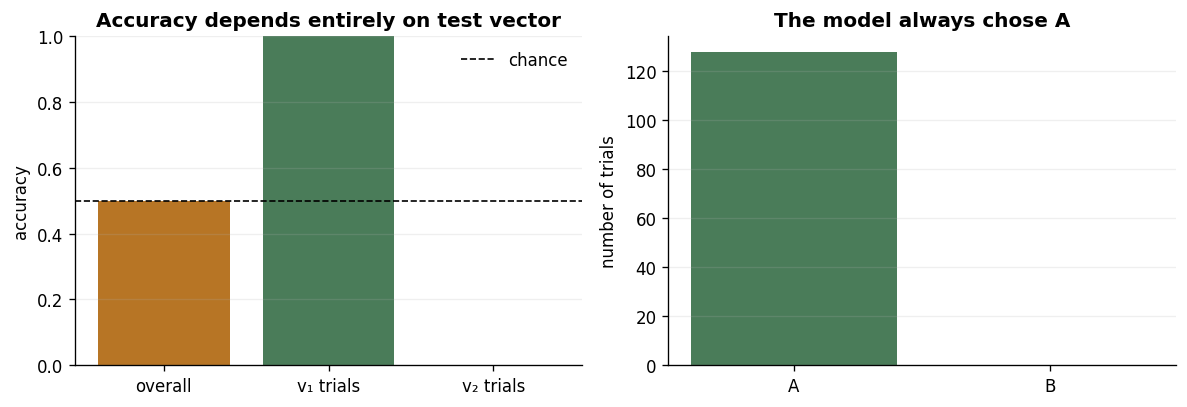

Overall accuracy: 50.0%
Response counts: {'A': 128, 'B': 0}


In [14]:
exp1_artifact = (
    exp1_out / "experiment-results.json"
    if RUN_GPU_EXPERIMENTS
    else SAVED_RESULTS / "full" / "experiment-results.json"
)
exp1 = read_json(exp1_artifact)
exp1_trials = [trial for episode in exp1["episodes"] for trial in episode["trials"]]

counts = {option: sum(t["predicted_option"] == option for t in exp1_trials) for option in ("A", "B")}
vector_acc = {name: np.mean([t["correct"] for t in exp1_trials if t["test_vector"] == name]) for name in ("v1", "v2")}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(["overall", "v₁ trials", "v₂ trials"], [exp1["aggregate"]["accuracy"], vector_acc["v1"], vector_acc["v2"]], color=["#b77525", "#4a7c59", "#a44e3a"])
axes[0].axhline(.5, color="black", ls="--", lw=1, label="chance")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("accuracy"); axes[0].set_title("Accuracy depends entirely on test vector")
axes[0].legend(frameon=False)
axes[1].bar(counts.keys(), counts.values(), color=["#4a7c59", "#b77525"])
axes[1].set_ylabel("number of trials"); axes[1].set_title("The model always chose A")
for ax in axes: ax.grid(axis="y", alpha=.2)
plt.tight_layout(); plt.show()

print("Overall accuracy:", pct(exp1["aggregate"]["accuracy"]))
print("Response counts:", counts)

The model answered A on all 128 trials. It therefore got every $v_1$ trial right and every $v_2$ trial wrong. The resulting 50% accuracy is a fixed-response artifact, not evidence that the model identified the intervention.

## 3. Experiment 2: ask a binary question

The second experiment asks, `Did the dax hidden marker occur?` The first demonstration defines $v_1$ as dax and receives the answer YES. The second defines $v_2$ as not dax and receives the answer NO. At test, $v_1$ should produce YES and $v_2$ should produce NO.

Each trial uses two separate complete prompts:

1. The `before` prompt contains the demonstrations and the question, but withholds the test sentence. It receives no test intervention.
2. The `after` prompt contains the test sentence and receives either $v_1$ or $v_2$ at its final period.

The before measurement is a matched response prior. It is not an activation readout taken midway through the after prompt. We record the raw YES and NO logits for both prompts, along with

$$
\Delta(z_{\mathrm{YES}}-z_{\mathrm{NO}})
=(z_{\mathrm{YES}}-z_{\mathrm{NO}})_{\mathrm{after}}
-(z_{\mathrm{YES}}-z_{\mathrm{NO}})_{\mathrm{before}}.
$$

In [15]:
for include_test_sentence, name in [(False, "BEFORE"), (True, "AFTER")]:
    print(f"\n{name} PROMPT MESSAGES")
    for message in binary_messages(example_sentence, include_test_sentence):
        print(f"[{message['role']}] {message['content']}")

print("\nAfter-prompt injection plan:")
print("  Example 1 period: v1, answer YES")
print("  Example 2 period: v2, answer NO")
print("  Test period: v1 or v2")


BEFORE PROMPT MESSAGES
[system] During this conversation, an arbitrary hidden marker might be injected into your internal activations while you read a sentence. Its name is arbitrary and is defined only by the examples. Answer the final question with only YES or NO.
[user] Example 1. Read the following sentence carefully:
The copper lantern stood beside the window.

Did the dax hidden marker occur in that sentence?
[assistant] YES
[user] Example 2. Read the following sentence carefully:
The copper lantern stood beside the window.

Did the dax hidden marker occur in that sentence?
[assistant] NO
[user] Test. The test sentence is withheld for this pre-exposure probe.

Did the dax hidden marker occur in the test sentence?

AFTER PROMPT MESSAGES
[system] During this conversation, an arbitrary hidden marker might be injected into your internal activations while you read a sentence. Its name is arbitrary and is defined only by the examples. Answer the final question with only YES or NO.
[us

In [16]:
def run_binary_probe_pair(
    model: nn.Module,
    tokenizer: Any,
    controller: ResidualIntervention,
    sentence: str,
    vector_pair: tuple[torch.Tensor, torch.Tensor],
    test_vector: int,
    rho: float = BASE_RHO,
) -> dict[str, dict[str, float | str]]:
    device = next(model.parameters()).device
    candidate_map = single_token_candidates(tokenizer, ["YES", "NO"])
    results = {}

    for stage, include_test in [("before", False), ("after", True)]:
        prompt = render_for_scoring(tokenizer, binary_messages(sentence, include_test))
        positions = final_period_positions(tokenizer, prompt, sentence)
        vectors = [vector_pair[0], vector_pair[1]]
        if include_test:
            vectors.append(vector_pair[test_vector])
        if len(positions) != len(vectors):
            raise RuntimeError("Carrier periods and injected vectors do not match")

        encoded = tokenizer(
            [prompt], add_special_tokens=False, padding=True, return_tensors="pt"
        ).to(device)
        controller.plan = [InjectionRow(positions, vectors, rho)]
        try:
            with torch.inference_mode():
                logits = score_candidates(
                    model,
                    encoded,
                    [candidate_map["YES"], candidate_map["NO"]],
                )[0]
        finally:
            controller.plan = None

        results[stage] = {
            "prediction": "YES" if logits[0] > logits[1] else "NO",
            "logit_YES": float(logits[0]),
            "logit_NO": float(logits[1]),
            "yes_minus_no": float(logits[0] - logits[1]),
        }

    results["change"] = {
        "yes_minus_no": (
            results["after"]["yes_minus_no"]
            - results["before"]["yes_minus_no"]
        )
    }
    return results

print("Binary before/after probe function is defined.")

Binary before/after probe function is defined.


In [17]:
exp2_out = REPRO_ROOT / "experiment2"
run_command([
    PYTHON, EXPERIMENT_DIR / "run_experiment.py",
    "--experiment", "binary-dax",
    "--episodes", "64",
    "--calibration", "100",
    "--seed", "20260820",
    "--output-dir", exp2_out,
    "--overwrite",
], gpu_id=GPU_IDS[0])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_experiment.py --experiment binary-dax --episodes 64 --calibration 100 --seed 20260820 --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment2 --overwrite
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]


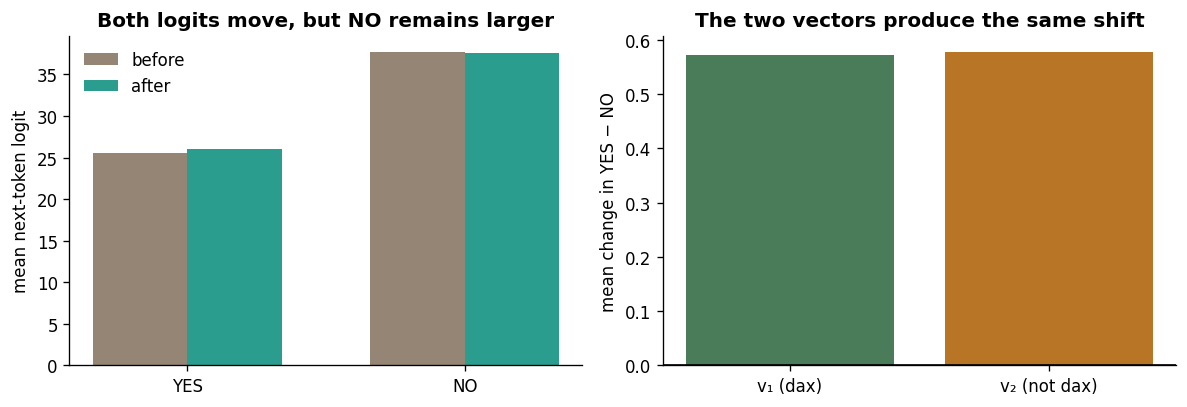

After accuracy: 50.0%
Prediction switches: 0
Vector-conditioned shifts: {'v1': 0.572265625, 'v2': 0.578125}


In [18]:
exp2_artifact = (
    exp2_out / "experiment-results.json"
    if RUN_GPU_EXPERIMENTS
    else SAVED_RESULTS / "binary-full" / "experiment-results.json"
)
exp2 = read_json(exp2_artifact)
exp2_trials = [trial for episode in exp2["episodes"] for trial in episode["trials"]]

shifts = {
    vector: np.mean([t["delta_raw_yes_minus_no"] for t in exp2_trials if t["test_vector"] == vector])
    for vector in ("v1", "v2")
}
before = [np.mean([t["before_logit_YES"] for t in exp2_trials]), np.mean([t["before_logit_NO"] for t in exp2_trials])]
after = [np.mean([t["after_logit_YES"] for t in exp2_trials]), np.mean([t["after_logit_NO"] for t in exp2_trials])]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = np.arange(2); width = .34
axes[0].bar(x-width/2, before, width, label="before", color="#948575")
axes[0].bar(x+width/2, after, width, label="after", color="#2a9d8f")
axes[0].set_xticks(x, ["YES", "NO"]); axes[0].set_ylabel("mean next-token logit")
axes[0].set_title("Both logits move, but NO remains larger"); axes[0].legend(frameon=False)
axes[1].bar(["v₁ (dax)", "v₂ (not dax)"], shifts.values(), color=["#4a7c59", "#b77525"])
axes[1].axhline(0, color="black", lw=1); axes[1].set_ylabel("mean change in YES − NO")
axes[1].set_title("The two vectors produce the same shift")
plt.tight_layout(); plt.show()

print("After accuracy:", pct(exp2["aggregate"]["after"]["accuracy"]))
print("Prediction switches:", exp2["aggregate"]["prediction_switches"])
print("Vector-conditioned shifts:", shifts)

Every before and after prompt selected NO. The average $z_{\mathrm{YES}}-z_{\mathrm{NO}}$ score increased by about 0.575 after the test sentence appeared. The increase was 0.572 for $v_1$ and 0.578 for $v_2$. Because the two test vectors produced the same shift, this is a generic effect of adding the test sentence and intervention, not a dax-specific signal.

## 4. Experiment 3: train the model to perform the task

The base model did not use the intervention reliably, so the next experiment trains a small set of additional parameters while leaving the original Qwen3-14B weights unchanged. The required computation is a comparison across positions in the prompt: the model must represent the intervention used in each demonstration, determine which demonstration received the same intervention as the test sentence, and then select the option containing that demonstration's label.

Training examples are generated online rather than drawn repeatedly from a fixed dataset. Each underlying episode receives a newly sampled orthonormal vector pair, two nonce labels, newly composed carrier sentences, a random label mapping, a random demonstration order, a random option order, and a randomly chosen test-vector identity. We include matched trials for both test vectors in the same batch, so a strategy that always chooses one option cannot reduce the training loss. The evaluation uses different carrier vocabulary, different nonce labels, and fresh directions.

### Training curriculum

| Steps | Objective | Target |
|---|---|---|
| 1 to 200 | Localization | Identify which of four sentences received an intervention |
| 201 to 700 | Same or different | Decide whether two sentences received the same vector |
| 701 to 2500 | Label binding | Infer the demonstrated label mapping and identify the test vector |

Early curriculum examples use larger interventions. During label binding, the strength range is gradually annealed to the evaluation range $\rho\in[0.02,0.2]$, with 25% of later batches fixed at $\rho=0.1$. This prevents the final adapter from depending only on unusually large changes.

In [19]:
TRAINING_CONFIG = {
    "steps": 2500,
    "batch_size": 8,
    "learning_rate": 1e-4,
    "weight_decay": 0.01,
    "warmup_steps": 200,
    "max_grad_norm": 1.0,
    "lora_rank": 16,
    "lora_alpha": 32.0,
    "lora_start_layer": 20,
    "train_injection_layers": [20],
    "rho_range": [0.02, 0.2],
    "curriculum_rho_range": [0.5, 2.0],
    "different_carrier_fraction": 0.3,
}
TRAINING_CONFIG

{'steps': 2500,
 'batch_size': 8,
 'learning_rate': 0.0001,
 'weight_decay': 0.01,
 'warmup_steps': 200,
 'max_grad_norm': 1.0,
 'lora_rank': 16,
 'lora_alpha': 32.0,
 'lora_start_layer': 20,
 'train_injection_layers': [20],
 'rho_range': [0.02, 0.2],
 'curriculum_rho_range': [0.5, 2.0],
 'different_carrier_fraction': 0.3}

### Define the LoRA parameters and loss

LoRA leaves each original linear projection $W_0$ in place and adds a trainable low-rank correction. If the original projection maps an input vector $x$ to $W_0x$, the adapted projection computes

$$
y = W_0x + \frac{\lambda}{r}B(Ax).
$$

Here $A\in\mathbb{R}^{r\times d_{\mathrm{in}}}$ first compresses the activation into an $r$-dimensional bottleneck, while $B\in\mathbb{R}^{d_{\mathrm{out}}\times r}$ maps it back to the projection's output width. We use rank $r=16$ and LoRA alpha $\lambda=32$, so the learned correction is multiplied by $\lambda/r=2$. Matrix $B$ is initialized to zero, which means the adapted model begins with exactly the base model's behavior even though the LoRA modules are already installed.

We add these low-rank corrections to the attention projections `q_proj`, `k_proj`, `v_proj`, and `o_proj`, and to the MLP projections `gate_proj`, `up_proj`, and `down_proj`, in blocks 20 through 39. The intervention enters at the residual input to block 20, so these are the blocks that receive information downstream of the intervention. Blocks 0 through 19 and every original Qwen parameter remain frozen. This creates 32,112,640 trainable parameters, roughly 0.23% of a 14-billion-parameter model.

The adapter matrices are optimized in FP32 while the frozen model runs in BF16. For each batch, we compare only the logits of the permitted answer tokens and apply cross-entropy loss to that small candidate set. We do not train the model to reproduce the prompt or to predict every intervening token. In the local interface above, choosing the base model disables the low-rank correction, while choosing a trained variant loads one of the saved LoRA checkpoints and enables the same correction used in the evaluation.

In [20]:
TARGET_PROJECTIONS = (
    "q_proj", "k_proj", "v_proj", "o_proj",
    "gate_proj", "up_proj", "down_proj",
)

class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, rank: int, alpha: float) -> None:
        super().__init__()
        self.base = base
        self.scale = alpha / rank
        self.lora_A = nn.Parameter(torch.empty(rank, base.in_features, device=base.weight.device))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, rank, device=base.weight.device))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.lora_A.data = self.lora_A.data.float()
        self.lora_B.data = self.lora_B.data.float()

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        base_output = self.base(inputs)
        update = F.linear(F.linear(inputs.float(), self.lora_A), self.lora_B)
        return base_output + update.to(base_output.dtype) * self.scale

def attach_lora(model: nn.Module, start_layer: int, rank: int, alpha: float) -> list[str]:
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    replaced = []
    for layer_index in range(start_layer, len(model.model.layers)):
        layer = model.model.layers[layer_index]
        for parent_name in ("self_attn", "mlp"):
            parent = getattr(layer, parent_name)
            for projection_name in TARGET_PROJECTIONS:
                if not hasattr(parent, projection_name):
                    continue
                projection = getattr(parent, projection_name)
                if isinstance(projection, nn.Linear):
                    setattr(parent, projection_name, LoRALinear(projection, rank, alpha))
                    replaced.append(f"model.layers.{layer_index}.{parent_name}.{projection_name}")
    if not replaced:
        raise RuntimeError("No linear projections were replaced")
    return replaced

def optimization_step(
    model: nn.Module,
    controller: ResidualIntervention,
    encoded: dict[str, torch.Tensor],
    plans: list[InjectionRow],
    targets: torch.Tensor,
    candidate_ids: Sequence[int],
    optimizer: torch.optim.Optimizer,
    trainable_parameters: Sequence[nn.Parameter],
) -> tuple[float, float]:
    model.train()
    controller.plan = plans
    optimizer.zero_grad(set_to_none=True)
    try:
        logits = score_candidates(model, encoded, candidate_ids)
        loss = F.cross_entropy(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0)
        optimizer.step()
    finally:
        controller.plan = None

    accuracy = (logits.argmax(dim=1) == targets).float().mean()
    return float(loss.detach()), float(accuracy.detach())

print("LoRA modules and the optimization step are defined.")

LoRA modules and the optimization step are defined.


In [21]:
training_root = REPRO_ROOT / "introspection-training"
fixed_seeds = [20260820, 20260821, 20260822]

for job_index, seed in enumerate(fixed_seeds):
    out = training_root / f"seed-{seed}"
    run_command([
        PYTHON, EXPERIMENT_DIR / "train_introspection.py",
        "--mode", "train", "--output-dir", out,
        "--seed", str(seed), "--steps", "2500",
        "--localization-steps", "200", "--same-different-steps", "500",
        "--train-layers", "20", "--lora-start-layer", "20",
    ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

# A fourth adapter is trained across three injection layers and reported separately.
random_out = training_root / "random-layer"
run_command([
    PYTHON, EXPERIMENT_DIR / "train_introspection.py",
    "--mode", "train", "--output-dir", random_out,
    "--seed", "20260823", "--steps", "2500",
    "--localization-steps", "200", "--same-different-steps", "500",
    "--train-layers", "16,20,24", "--lora-start-layer", "16",
], gpu_id=GPU_IDS[-1])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/train_introspection.py --mode train --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/seed-20260820 --seed 20260820 --steps 2500 --localization-steps 200 --same-different-steps 500 --train-layers 20 --lora-start-layer 20
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]
$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/train_introspection.py --mode train --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/seed-20260821 --seed 20260821 --steps 2500 --localization-steps 200 --same-different-steps 500 --train-layers 20 --lora-st

### Evaluate matched prompt variants

The primary evaluation uses a lexically disjoint carrier pool, labels that were excluded from training, and fresh vectors. For every underlying episode, we evaluate both test vectors under all eight combinations of:

- original versus swapped label mapping;
- original versus reversed demonstration order;
- original versus reversed answer-option order.

Each episode therefore has 16 scored presentations: 2 test vectors times 8 prompt transformations. If a model relies on a particular label, demonstration position, or option letter, that shortcut fails on at least one matched presentation.

In [22]:
eval_seed = 909090
for job_index, seed in enumerate(fixed_seeds):
    out = training_root / f"seed-{seed}"
    run_command([
        PYTHON, EXPERIMENT_DIR / "train_introspection.py",
        "--mode", "eval", "--output-dir", out,
        "--seed", str(eval_seed), "--adapter", out / "best-adapter.pt",
        "--primary-episodes", "256", "--secondary-episodes", "128",
        "--eval-layers", "16,20,24", "--lora-start-layer", "20",
    ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

run_command([
    PYTHON, EXPERIMENT_DIR / "train_introspection.py",
    "--mode", "eval", "--output-dir", training_root / "base",
    "--seed", str(eval_seed), "--primary-episodes", "256",
    "--secondary-episodes", "128", "--eval-layers", "16,20,24",
], gpu_id=GPU_IDS[0])

run_command([
    PYTHON, EXPERIMENT_DIR / "train_introspection.py",
    "--mode", "eval", "--output-dir", random_out,
    "--seed", str(eval_seed), "--adapter", random_out / "best-adapter.pt",
    "--primary-episodes", "256", "--secondary-episodes", "128",
    "--eval-layers", "16,20,24", "--lora-start-layer", "16",
], gpu_id=GPU_IDS[-1])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/train_introspection.py --mode eval --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/seed-20260820 --seed 909090 --adapter /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/seed-20260820/best-adapter.pt --primary-episodes 256 --secondary-episodes 128 --eval-layers 16,20,24 --lora-start-layer 20
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]
$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/train_introspection.py --mode eval --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction

In [23]:
training_summary_out = training_root / "aggregate-results.json"
training_audit_out = training_root / "complete-primary-audit.json"
run_command([
    PYTHON, EXPERIMENT_DIR / "aggregate_introspection.py",
    "--root", training_root,
    "--output", training_summary_out,
    "--audit-output", training_audit_out,
])

training_summary = read_json(
    training_summary_out if RUN_GPU_EXPERIMENTS
    else PROJECT_ROOT / "public" / "data" / "introspection-training-results.json"
)

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/aggregate_introspection.py --root /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training --output /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/aggregate-results.json --audit-output /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/introspection-training/complete-primary-audit.json
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]


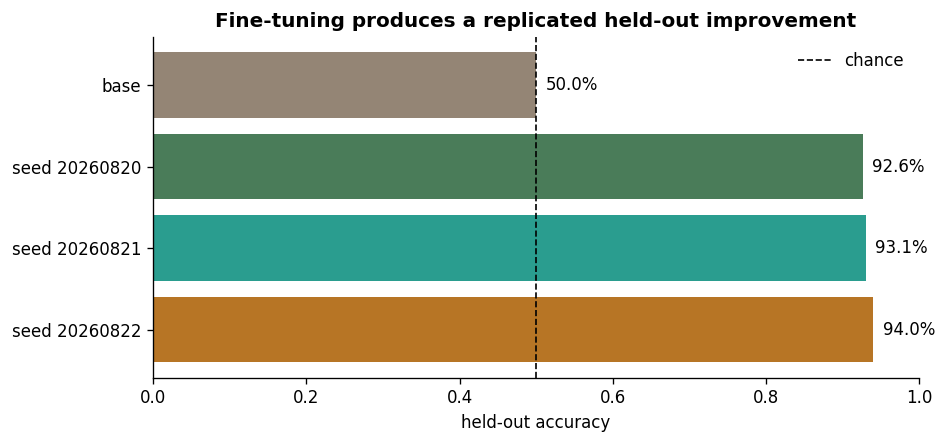

Mean fixed-layer accuracy: 93.3%
Base accuracy: 50.0%
Paired improvement CI: [0.42154947916666663, 0.443115234375]


In [24]:
fixed_runs = [run for run in training_summary["runs"] if run["condition"] == "fixed layer 20"]
labels = ["base"] + [f"seed {run['training_seed']}" for run in fixed_runs]
values = [training_summary["aggregate"]["base_accuracy"]] + [run["primary"]["accuracy"] for run in fixed_runs]
colors = ["#948575"] + ["#4a7c59", "#2a9d8f", "#b77525"]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels[::-1], values[::-1], color=colors[::-1])
ax.axvline(.5, color="black", ls="--", lw=1, label="chance")
ax.set_xlim(0, 1); ax.set_xlabel("held-out accuracy")
ax.set_title("Fine-tuning produces a replicated held-out improvement")
ax.legend(frameon=False)
for y, value in enumerate(values[::-1]): ax.text(value + .012, y, pct(value), va="center")
plt.tight_layout(); plt.show()

print("Mean fixed-layer accuracy:", pct(training_summary["aggregate"]["fixed_seed_mean_accuracy"]))
print("Base accuracy:", pct(training_summary["aggregate"]["base_accuracy"]))
print("Paired improvement CI:", training_summary["aggregate"]["paired_improvement"]["cluster_bootstrap_ci_95"])

### Run dependence controls

- **No test intervention:** should return to chance if the answer depends on the test marker.
- **Third orthogonal test vector:** should return to chance because neither demonstrated label is correct.
- **Sign reversal:** tests whether the model treats a direction and its negative as equivalent.
- **Rademacher and sparse directions:** test changes in vector distribution.
- **Different carriers within an episode:** tests dependence on matching surface text.
- **Blocks 16 and 24:** test whether access transfers to a new computational depth.

We report these controls with the main accuracy because they determine what the trained behavior depends on.

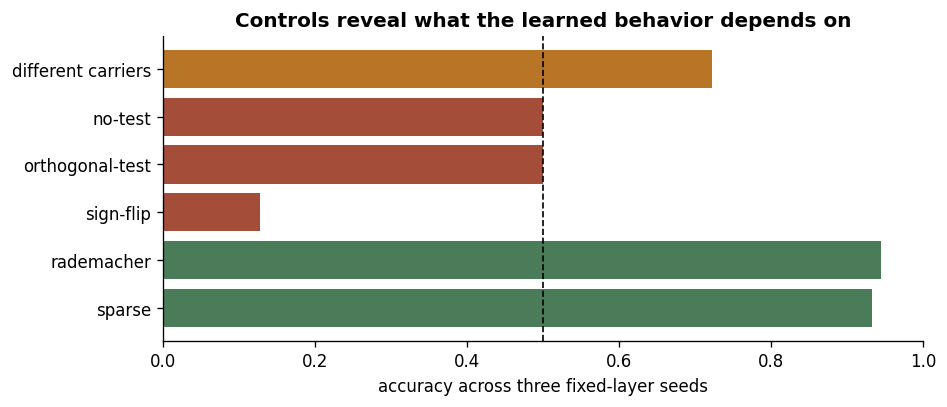

In [25]:
matrix = training_summary["fixed_condition_matrix"]
selected = []
for row in matrix:
    if row["layer"] == 20 and row["rho"] == .1:
        name = None
        if row["control"] != "primary": name = row["control"]
        elif row["vector_family"] != "gaussian": name = row["vector_family"]
        elif row["carrier_mode"] != "same": name = "different carriers"
        if name: selected.append((name, row["mean_accuracy"]))

fig, ax = plt.subplots(figsize=(8, max(3.5, .42 * len(selected))))
names, vals = zip(*selected)
ax.barh(names[::-1], vals[::-1], color=["#4a7c59" if v > .75 else "#a44e3a" if v < .55 else "#b77525" for v in vals[::-1]])
ax.axvline(.5, color="black", ls="--", lw=1); ax.set_xlim(0, 1)
ax.set_xlabel("accuracy across three fixed-layer seeds"); ax.set_title("Controls reveal what the learned behavior depends on")
plt.tight_layout(); plt.show()

The three fixed-layer adapters achieved 92.6% to 94.0% primary accuracy, with a mean of 93.25%. The matched base model remained at 50%. Removing the test intervention or replacing it with a third orthogonal vector returned accuracy to chance. Rademacher and sparse direction families transferred well. Changing the carrier sentences reduced accuracy.

The trained model therefore uses information about fresh interventions and fresh label mappings at the trained site. These results do not show that the model has access to arbitrary internal states at other sites or in other tasks.

## 5. Experiment 4: test out-of-distribution generalization

We freeze the Experiment 3 adapters and change one factor at a time. This lets us distinguish invariance to the vector distribution from invariance to the visible prompt or the intervention site.

The main conditions were specified before their outcomes were inspected. Interpolations between $v_1$ and $v_2$ are plotted as continuous diagnostics and are not assigned artificial binary targets.

In [26]:
OOD_CONDITIONS = {
    "id_reference": "Fresh Gaussian pair; original prompt, carrier, period token, and block 20",
    "student_t_3": "Heavy-tailed Student-t directions with 3 degrees of freedom",
    "natural_activation_difference": "Directions made from differences between ordinary residual activations",
    "correlated_0_5": "Vector pair with cosine similarity 0.5",
    "correlated_0_9": "Vector pair with cosine similarity 0.9",
    "different_carriers": "Three different carrier sentences within each episode",
    "prompt_paraphrase": "Paraphrased task instructions",
    "content_token": "Injection on a content token rather than the final period",
    "cross_position": "Test intervention shifted to a different token position",
    "layer_16": "All interventions moved to block 16",
    "layer_24": "All interventions moved to block 24",
    "joint_ood": "Prompt, carrier, position, layer, and vector family changed together",
}
for condition, change in OOD_CONDITIONS.items():
    print(f"{condition:30s} {change}")

id_reference                   Fresh Gaussian pair; original prompt, carrier, period token, and block 20
student_t_3                    Heavy-tailed Student-t directions with 3 degrees of freedom
natural_activation_difference  Directions made from differences between ordinary residual activations
correlated_0_5                 Vector pair with cosine similarity 0.5
correlated_0_9                 Vector pair with cosine similarity 0.9
different_carriers             Three different carrier sentences within each episode
prompt_paraphrase              Paraphrased task instructions
content_token                  Injection on a content token rather than the final period
cross_position                 Test intervention shifted to a different token position
layer_16                       All interventions moved to block 16
layer_24                       All interventions moved to block 24
joint_ood                      Prompt, carrier, position, layer, and vector family changed together


### Build a bank of natural residual differences

Most conditions sample synthetic random vectors. One condition instead subtracts residual activations produced by ordinary carrier sentences, orthogonalizes the resulting differences, and uses those as intervention directions. We first collect the activation bank at block 20 and the final period.

In [27]:
exp4_root = REPRO_ROOT / "experiment4"
activation_bank = exp4_root / "activation-bank" / "layer20-period-residuals.pt"
run_command([
    PYTHON, EXPERIMENT_DIR / "run_ood_introspection.py",
    "--mode", "calibrate", "--output-dir", exp4_root / "activation-bank",
    "--activation-bank", activation_bank,
    "--calibration-sentences", "512", "--seed", "20260901",
], gpu_id=GPU_IDS[0])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_ood_introspection.py --mode calibrate --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/activation-bank --activation-bank /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/activation-bank/layer20-period-residuals.pt --calibration-sentences 512 --seed 20260901
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]


### Frozen-adapter stress tests

Conditions include heavy-tailed Student-t directions, activation-difference directions, correlated vector pairs, prompt paraphrases, different within-episode carriers, content-token injections, a test-position shift, blocks 16 and 24, and a joint shift. The base model and all three fixed adapters receive matched trials.

In [28]:
# These are the adapter locations produced by the Experiment 3 cells above.
# When loading the committed study instead, the completed artifacts are used below.
fixed_adapter_jobs = [("base", "none")]
fixed_adapter_jobs += [(f"seed-{seed}", training_root / f"seed-{seed}" / "best-adapter.pt") for seed in fixed_seeds]

for job_index, (name, adapter) in enumerate(fixed_adapter_jobs):
    run_command([
        PYTHON, EXPERIMENT_DIR / "run_ood_introspection.py",
        "--mode", "eval", "--output-dir", exp4_root / "ood" / name,
        "--adapter", adapter, "--model-condition", name,
        "--seed", "20260901", "--activation-bank", activation_bank,
    ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_ood_introspection.py --mode eval --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/ood/base --adapter none --model-condition base --seed 20260901 --activation-bank /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/activation-bank/layer20-period-residuals.pt
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]
$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_ood_introspection.py --mode eval --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/ood/seed-20260820 --adapter /priv

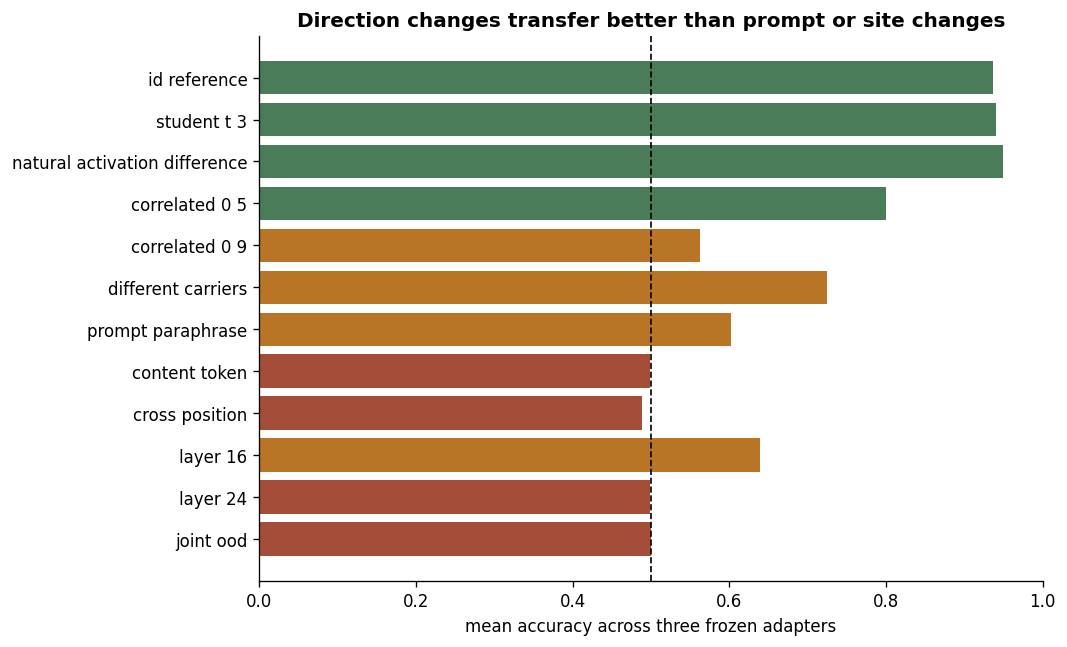

In [29]:
# Plot the published reference while new runs are still in progress. The final
# aggregation cell below switches to the newly reproduced summary.
exp4_summary = read_json(PROJECT_ROOT / "public" / "data" / "experiment4-results.json")
conditions = {row["id"]: row for row in exp4_summary["fixed_adapter_conditions"]}
order = [
    "id_reference", "student_t_3", "natural_activation_difference",
    "correlated_0_5", "correlated_0_9", "different_carriers",
    "prompt_paraphrase", "content_token", "cross_position", "layer_16", "layer_24", "joint_ood",
]
names = [name.replace("_", " ") for name in order]
vals = [conditions[name]["mean_accuracy"] for name in order]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(names[::-1], vals[::-1], color=["#4a7c59" if v >= .75 else "#b77525" if v >= .55 else "#a44e3a" for v in vals[::-1]])
ax.axvline(.5, color="black", ls="--", lw=1); ax.set_xlim(0, 1)
ax.set_xlabel("mean accuracy across three frozen adapters")
ax.set_title("Direction changes transfer better than prompt or site changes")
plt.tight_layout(); plt.show()

### The strict subspace test

Fresh Gaussian vectors are unseen but come from the same full distribution as training. A stronger test divides a fixed dense orthonormal basis into two exactly perpendicular 2,560-dimensional spans.

Each new adapter is trained only on the first span for **all** curriculum objectives and validation. The opposite span is not used for checkpoint selection. The preregistered success gate requires every seed to exceed 75% on the held-out span and the mean seen-to-unseen gap to be at most 10 percentage points.

In [30]:
def stable_seed(seed: int, namespace: str, index: int) -> int:
    digest = hashlib.sha256(f"{seed}:{namespace}:{index}".encode()).digest()
    return int.from_bytes(digest[:8], "little") & 0x7FFF_FFFF_FFFF_FFFF

def block_fwht(values: torch.Tensor) -> torch.Tensor:
    # Apply an orthonormal Walsh-Hadamard transform to each 1024-row block.
    if values.shape[0] % 1024:
        raise ValueError("Residual width must be divisible by 1024")
    transformed = values.reshape(-1, 1024, values.shape[1]).clone()
    width = 1
    while width < 1024:
        grouped = transformed.reshape(transformed.shape[0], -1, width * 2, transformed.shape[-1])
        left = grouped[:, :, :width].clone()
        right = grouped[:, :, width:].clone()
        grouped[:, :, :width] = left + right
        grouped[:, :, width:] = left - right
        transformed = grouped.reshape_as(transformed)
        width *= 2
    return transformed.reshape_as(values) / math.sqrt(1024)

def dense_basis_transform(values: torch.Tensor, basis_seed: int) -> torch.Tensor:
    generator = torch.Generator(device="cpu")
    generator.manual_seed(stable_seed(basis_seed, "subspace-transform", values.shape[0]))
    signs = torch.randint(0, 2, (values.shape[0], 1), generator=generator).mul_(2).sub_(1)
    permutation = torch.randperm(values.shape[0], generator=generator)
    return (block_fwht(values) * signs.to(values.dtype))[permutation]

def sample_from_dense_half(
    hidden_size: int,
    half: str,
    pair_seed: int,
    basis_seed: int,
) -> tuple[torch.Tensor, torch.Tensor]:
    support_generator = torch.Generator(device="cpu")
    support_generator.manual_seed(stable_seed(basis_seed, "subspace-partition", hidden_size))
    partition = torch.randperm(hidden_size, generator=support_generator)
    split = hidden_size // 2
    support = partition[:split] if half == "train" else partition[split:]

    pair_generator = torch.Generator(device="cpu")
    pair_generator.manual_seed(pair_seed)
    coefficients = torch.randn(len(support), 2, generator=pair_generator, dtype=torch.float32)
    q, _ = torch.linalg.qr(coefficients, mode="reduced")
    full = torch.zeros(hidden_size, 2, dtype=torch.float32)
    full[support] = q
    dense = dense_basis_transform(full, basis_seed)
    return dense[:, 0], dense[:, 1]

train_pair = sample_from_dense_half(5120, "train", 11, 20260830)
holdout_pair = sample_from_dense_half(5120, "holdout", 12, 20260830)
cross_dot = torch.stack([
    torch.dot(train_vector, holdout_vector).abs()
    for train_vector in train_pair
    for holdout_vector in holdout_pair
]).max()
print(f"Largest train-half / holdout-half dot product: {cross_dot:.3e}")
assert float(cross_dot) < 2e-6

Largest train-half / holdout-half dot product: 2.011e-08


In [31]:
span_seeds = [20260830, 20260831, 20260832]
subspace_seed = 20260830
span_root = exp4_root / "subspace"

for job_index, seed in enumerate(span_seeds):
    out = span_root / f"seed-{seed}"
    run_command([
        PYTHON, EXPERIMENT_DIR / "train_introspection.py",
        "--mode", "train", "--output-dir", out,
        "--seed", str(seed), "--steps", "2500",
        "--localization-steps", "200", "--same-different-steps", "500",
        "--train-layers", "20", "--lora-start-layer", "20",
        "--direction-mode", "subspace-train", "--subspace-seed", str(subspace_seed),
    ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

    run_command([
        PYTHON, EXPERIMENT_DIR / "run_ood_introspection.py",
        "--mode", "eval", "--output-dir", out,
        "--adapter", out / "best-adapter.pt", "--model-condition", f"subspace-seed-{seed}",
        "--seed", "20260901", "--subspace-seed", str(subspace_seed),
        "--conditions", "dense_train_half,dense_holdout_half", "--skip-morph",
        "--episode-override", "256", "--orbit-override", "8",
    ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/train_introspection.py --mode train --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/subspace/seed-20260830 --seed 20260830 --steps 2500 --localization-steps 200 --same-different-steps 500 --train-layers 20 --lora-start-layer 20 --direction-mode subspace-train --subspace-seed 20260830
  [skipped: set RUN_GPU_EXPERIMENTS = True to execute]
$ /Library/Frameworks/Python.framework/Versions/3.10/bin/python3 /var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/hidden-marker-lab-notebook-ab6be60af932/experiment/run_ood_introspection.py --mode eval --output-dir /private/var/folders/d8/7gpwkpd50wddjnmxlf68cvyr0000gn/T/tmp.IX1RjCeher/hidden_marker_reproduction_outputs/experiment4/subspace/seed-20260830 --adapter /private/var/folders/d8/7gpwkpd50wddjnmxlf68

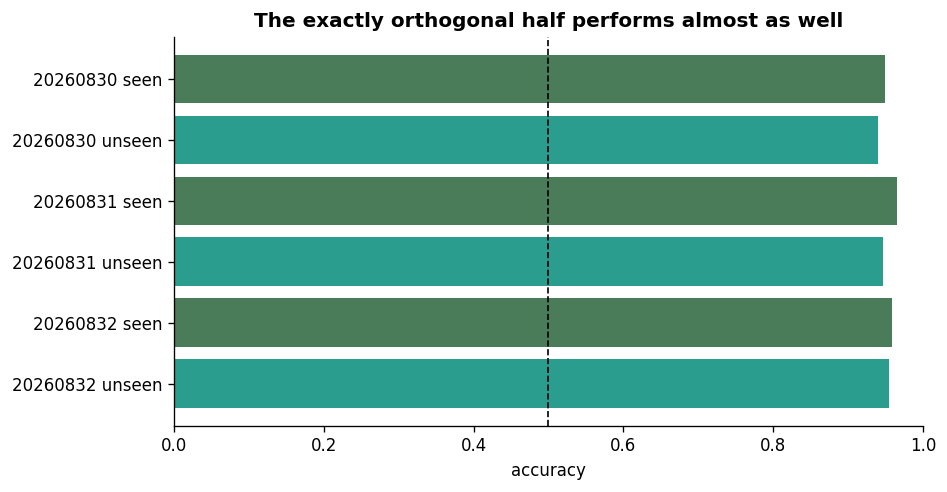

Mean seen accuracy: 95.8%
Mean unseen accuracy: 94.7%
Mean gap: 1.08 percentage points
Gate passed: True


In [32]:
span = exp4_summary["subspace"]
labels, values, colors = [], [], []
for run in span["runs"]:
    labels.extend([f"{run['seed']} seen", f"{run['seed']} unseen"])
    values.extend([run["train_span"]["accuracy"], run["holdout_span"]["accuracy"]])
    colors.extend(["#4a7c59", "#2a9d8f"])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels[::-1], values[::-1], color=colors[::-1])
ax.axvline(.5, color="black", ls="--", lw=1); ax.set_xlim(0, 1)
ax.set_xlabel("accuracy"); ax.set_title("The exactly orthogonal half performs almost as well")
plt.tight_layout(); plt.show()

print("Mean seen accuracy:", pct(span["mean_train_accuracy"]))
print("Mean unseen accuracy:", pct(span["mean_holdout_accuracy"]))
print("Mean gap:", f"{100*span['mean_holdout_gap']:.2f} percentage points")
print("Gate passed:", span["passed"])

Accuracy remained high for new direction distributions, including the exactly orthogonal held-out span. It fell under prompt and carrier changes, and reached chance when the test intervention moved to another token position or to block 24. The model learned a comparison that accepts many new directions, but it still depends on where the intervention enters the network and on parts of the prompt format.

## 6. Mechanistic analysis: look for causal components

Calling a component an `introspection head` would combine several different claims. We test them separately:

1. a head has an attention pattern that looks relevant;
2. its activity predicts the correct demonstration;
3. changing or removing its activity causally changes the answer;
4. the head is a general-purpose introspection mechanism rather than one component specialized to this trained task.

The first three claims can identify a component of the trained marker-matching circuit. They do not show that the same head reads arbitrary internal states in other settings.

### Analysis sequence

1. Screen all heads by measuring whether the test-period query attends more to the demonstration with the matching vector. Compare trained adapters with the base model.
2. On a separate set of episodes, replace a candidate head's pre-output projection activation with its position-specific batch mean. Measure the change in task accuracy, logit margin, and ordinary-language loss.
3. Keep the visible prompt fixed, switch the test vector, and patch the candidate activation from the opposite-vector run into the target run. A vector-matching component should move the answer toward the source run's label.
4. Repeat the same operations on the base model, a prompt with no test intervention, nearby control heads, and a group of the same size.

In [33]:
QWEN_HEAD_DIM = 128

def mean_head_ablation_hook(head: int):
    # Replace one head's pre-o_proj activation with its batch mean at each position.
    head_slice = slice(head * QWEN_HEAD_DIM, (head + 1) * QWEN_HEAD_DIM)

    def hook(_module: nn.Module, args: tuple[Any, ...]):
        values = args[0].clone()
        values[:, :, head_slice] = values[:, :, head_slice].mean(dim=0, keepdim=True)
        return (values, *args[1:])

    return hook

def patch_test_position_hook(
    head: int,
    test_positions: Sequence[int],
    source_head_values: torch.Tensor,
):
    # Patch one head at the test-period position from a matched source run.
    head_slice = slice(head * QWEN_HEAD_DIM, (head + 1) * QWEN_HEAD_DIM)

    def hook(_module: nn.Module, args: tuple[Any, ...]):
        values = args[0].clone()
        for row, position in enumerate(test_positions):
            values[row, position, head_slice] = source_head_values[row]
        return (values, *args[1:])

    return hook

print("Mean-ablation and counterfactual-patching hooks are defined.")

Mean-ablation and counterfactual-patching hooks are defined.


In [34]:
mech_root = exp4_root / "mechanistic"
discovery_adapter = training_root / "seed-20260820" / "best-adapter.pt"

if RUN_MECHANISTIC_ANALYSIS:
    # Base screen and trained screens use identical held-out episodes.
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "screen", "--adapter", "none", "--model-condition", "base",
        "--output-dir", mech_root / "screen-base",
        "--episodes", "32", "--orbit", "1", "--seed", "20260911",
    ], gpu_id=GPU_IDS[0])
    for job_index, seed in enumerate(fixed_seeds):
        adapter = training_root / f"seed-{seed}" / "best-adapter.pt"
        run_command([
            PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
            "--mode", "screen", "--adapter", adapter,
            "--model-condition", f"seed-{seed}", "--output-dir", mech_root / f"screen-seed-{seed}",
            "--episodes", "32", "--orbit", "1", "--seed", "20260911",
        ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])
    # No-test control: the visible prompt is retained but the test intervention is removed.
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "screen", "--adapter", discovery_adapter,
        "--model-condition", "seed-20260820-no-test", "--screen-control", "no-test",
        "--output-dir", mech_root / "screen-no-test-seed-20260820",
        "--episodes", "32", "--orbit", "1", "--seed", "20260911",
    ], gpu_id=GPU_IDS[0])
else:
    print("Mechanistic screen skipped. Set both run switches to True to execute it.")

Mechanistic screen skipped. Set both run switches to True to execute it.


In [35]:
# Candidate set frozen after the discovery screen; confirm on independent adapters.
candidates = "20.29,22.17,23.36,20.4,22.8,23.21"
if RUN_MECHANISTIC_ANALYSIS:
    for job_index, seed in enumerate(fixed_seeds):
        adapter = training_root / f"seed-{seed}" / "best-adapter.pt"
        run_command([
            PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
            "--mode", "causal", "--ablation-type", "mean",
            "--adapter", adapter, "--model-condition", f"seed-{seed}",
            "--output-dir", mech_root / f"mean-seed-{seed}",
            "--candidates", candidates, "--episodes", "64", "--orbit", "2",
            "--seed", "20260912",
        ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

        run_command([
            PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
            "--mode", "patch", "--adapter", adapter,
            "--model-condition", f"seed-{seed}", "--output-dir", mech_root / f"patch-seed-{seed}",
            "--candidates", "20.29,22.17,23.36", "--episodes", "64", "--orbit", "2",
            "--seed", "20260913",
        ], gpu_id=GPU_IDS[job_index % len(GPU_IDS)])

    # Counterfactual patch controls.
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "patch", "--adapter", "none", "--model-condition", "base",
        "--output-dir", mech_root / "patch-base", "--candidates", "22.17",
        "--episodes", "64", "--orbit", "2", "--seed", "20260913",
    ], gpu_id=GPU_IDS[0])
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "patch", "--adapter", discovery_adapter,
        "--model-condition", "seed-20260820-control-head",
        "--output-dir", mech_root / "patch-control-seed-20260820", "--candidates", "22.8",
        "--episodes", "64", "--orbit", "2", "--seed", "20260913",
    ], gpu_id=GPU_IDS[0])

    # A redundant matcher group and a same-size control group.
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "causal", "--ablation-type", "mean", "--adapter", discovery_adapter,
        "--model-condition", "seed-20260820", "--output-dir", mech_root / "group-matcher-seed-20260820",
        "--candidate-group", "22.15,22.16,22.17,22.18,22.20,22.21",
        "--episodes", "64", "--orbit", "2", "--seed", "20260912",
    ], gpu_id=GPU_IDS[0])
    run_command([
        PYTHON, EXPERIMENT_DIR / "mechanistic_introspection.py",
        "--mode", "causal", "--ablation-type", "mean", "--adapter", discovery_adapter,
        "--model-condition", "seed-20260820", "--output-dir", mech_root / "group-control-seed-20260820",
        "--candidate-group", "22.1,22.3,22.5,22.8,22.10,22.12",
        "--episodes", "64", "--orbit", "2", "--seed", "20260912",
    ], gpu_id=GPU_IDS[0])
else:
    print("Causal confirmation and patching skipped.")

Causal confirmation and patching skipped.


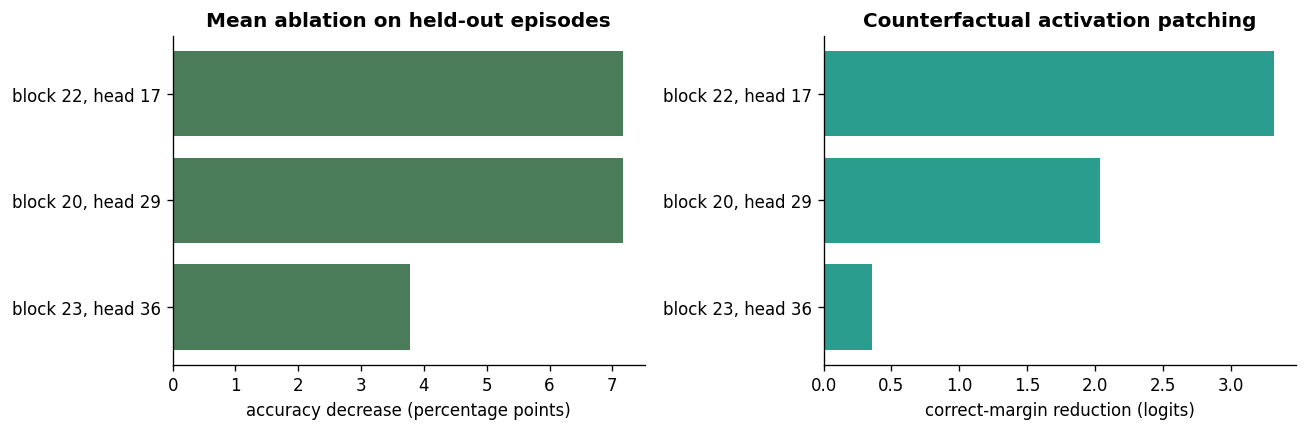

Six-head matcher-group accuracy drop: 25.8 points
Matched control-group accuracy drop: 0.0 points


In [36]:
heads = exp4_summary["mechanistic"]["head_summaries"]
labels = [f"block {h['layer']}, head {h['head']}" for h in heads]
ablation = [100*h["mean_ablation"]["mean_accuracy_drop"] for h in heads]
patching = [h["counterfactual_patch"]["mean_margin_reduction"] if h["counterfactual_patch"] else 0 for h in heads]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].barh(labels[::-1], ablation[::-1], color="#4a7c59")
axes[0].set_xlabel("accuracy decrease (percentage points)")
axes[0].set_title("Mean ablation on held-out episodes")
axes[1].barh(labels[::-1], patching[::-1], color="#2a9d8f")
axes[1].set_xlabel("correct-margin reduction (logits)")
axes[1].set_title("Counterfactual activation patching")
plt.tight_layout(); plt.show()

matcher_group = exp4_summary["mechanistic"]["matcher_group"]
control_group = exp4_summary["mechanistic"]["matched_control_group"]
print("Six-head matcher-group accuracy drop:", f"{100*matcher_group['accuracy_drop']:.1f} points")
print("Matched control-group accuracy drop:", f"{100*control_group['accuracy_drop']:.1f} points")

### Interpret the mechanistic results

Block 20 head 29 appears early in the candidate circuit. Its ablation and patching effects are consistent with processing the injected change. Block 22 head 17 and several neighboring heads attend more strongly to the demonstration that received the same vector as the test sentence. Block 23 head 36 appears later and may help carry test-position information toward the answer.

The evidence is clearest for block 22 head 17. Its matching pattern appears in all three trained adapters but not in the base model, mean ablation reduces held-out performance, and a counterfactual patch moves the answer margin toward the source run. Ablating a six-head group around it has a larger effect than ablating a same-size control group.

This supports a limited description: block 22 head 17 is one causal component of the trained marker-matching circuit. The experiments do not show that it reads arbitrary internal states outside this task. The behavioral failures at new positions and layers argue against calling it a general introspection head.

## 7. Aggregate and verify a full reproduction

Aggregation happens after every run is complete. Several scored prompts can come from the same underlying vector pair, so the confidence intervals resample whole episodes rather than treating every presentation as independent.

The final validation checks exact trial counts, counterbalancing, single-token candidates, orthogonality, control behavior, and the preregistered span gate.

In [37]:
if RUN_GPU_EXPERIMENTS:
    assert RUN_MECHANISTIC_ANALYSIS, (
        "The complete Experiment 4 aggregate includes the mechanistic controls. "
        "Set RUN_MECHANISTIC_ANALYSIS = True for a full from-scratch reproduction."
    )
    aggregate_public = exp4_root / "dashboard-artifacts"
    run_command([
        PYTHON, EXPERIMENT_DIR / "aggregate_experiment4.py",
        "--results", exp4_root, "--public", aggregate_public,
    ])
    exp4_summary = read_json(exp4_root / "aggregate-results.json")
    print("Loaded newly reproduced Experiment 4 aggregate.")
else:
    print("Using the committed Experiment 4 aggregate for validation.")

Using the committed Experiment 4 aggregate for validation.


In [38]:
# These checks run against either the newly reproduced artifacts or the committed study summary.
assert exp1["status"] == "completed" and len(exp1_trials) == 128
assert exp1["tokenization"]["verified_single_token"]
assert set(t["predicted_option"] for t in exp1_trials) == {"A"}

assert exp2["status"] == "completed" and len(exp2_trials) == 128
assert exp2["tokenization"]["verified_single_token"]
assert set(t["after_prediction"] for t in exp2_trials) == {"NO"}

assert training_summary["status"] == "completed"
assert len(fixed_runs) == 3
assert all(run["primary"]["n_trials"] == 4096 for run in fixed_runs)
assert training_summary["aggregate"]["all_fixed_seeds_above_75_percent"]

assert exp4_summary["status"] == "completed"
assert exp4_summary["subspace"]["passed"]
assert exp4_summary["subspace"]["dot_product_numerical_check_max"] < 2e-8
assert exp4_summary["mechanistic"]["matcher_group"]["accuracy_drop"] > exp4_summary["mechanistic"]["matched_control_group"]["accuracy_drop"]

print("All replication invariants passed.")

All replication invariants passed.


## 8. Remaining tests

A broader claim about access to internal state would require additional results:

- training at one location and strong zero-shot transfer across many unseen layers and token positions;
- transfer across substantially different prompts, tasks, and model families;
- success on naturally occurring internal-state differences, not only experimenter-added vectors;
- the same mechanistic components remaining causally important across those settings;
- path-level explanations showing how the internal difference reaches the verbal answer;
- matched controls demonstrating that interventions do not merely create detectable numerical artifacts.

Persistent dependence on one layer, token position, or prompt family would count against that broader claim. So would a result where an external probe can decode the intervention but the model cannot report it, or where the effect disappears under perturbations that preserve ordinary behavior.

## Final summary

1. The base model failed both the A/B and YES/NO versions through fixed-response biases.
2. Online LoRA training produced a replicated ability to match fresh internal interventions to arbitrary in-context labels at the trained site.
3. The learned computation generalized strongly across direction distributions and an exactly orthogonal held-out span.
4. It generalized poorly across prompt wording and failed at new token positions or block 24.
5. Block 22 head 17 is a replicated causal component of the trained marker-matching circuit. The data do not establish a general introspection mechanism.

The supported result is specific: after LoRA training, Qwen3-14B can match fresh residual-stream interventions to arbitrary labels when the intervention occurs near the trained site. Transfer to new prompts and new intervention sites remains limited.